In [1]:
import os
import random
import numpy as np
import tensorflow as tf

from pathlib import Path

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
TRAIN_DIR = Path(
    r"D:\Rice Final model\Dataset\Train"
)

VAL_DIR = Path(
    r"D:\Rice Final model\Dataset\Validation"
)

TEST_DIR = Path(
    r"D:\Rice Final model\Dataset\Test"
)

IMG_SIZE = 256
BATCH_SIZE = 8
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Training:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

Training: D:\Rice Final model\Dataset\Train
Validation: D:\Rice Final model\Dataset\Validation
Test: D:\Rice Final model\Dataset\Test


In [3]:
def get_classes(folder):

    return sorted([
        p.name
        for p in folder.iterdir()
        if p.is_dir()
    ])


train_classes = get_classes(TRAIN_DIR)
val_classes = get_classes(VAL_DIR)
test_classes = get_classes(TEST_DIR)

print("TRAIN:")
print(train_classes)

print("\nVALIDATION:")
print(val_classes)

print("\nTEST:")
print(test_classes)

print("\nNumber of training classes:", len(train_classes))
print("Number of validation classes:", len(val_classes))
print("Number of test classes:", len(test_classes))

assert train_classes == val_classes == test_classes, \
    "ERROR: Class folders are not identical!"

print("\n✓ ALL DATASETS HAVE IDENTICAL CLASS FOLDERS")

TRAIN:
['Bacterial Leaf Blight', 'Brown Narrow Leaf Spot', 'Brown Spot', 'Healthy', 'Leaf Scald', 'Rice Blast', 'Rice Hispa']

VALIDATION:
['Bacterial Leaf Blight', 'Brown Narrow Leaf Spot', 'Brown Spot', 'Healthy', 'Leaf Scald', 'Rice Blast', 'Rice Hispa']

TEST:
['Bacterial Leaf Blight', 'Brown Narrow Leaf Spot', 'Brown Spot', 'Healthy', 'Leaf Scald', 'Rice Blast', 'Rice Hispa']

Number of training classes: 7
Number of validation classes: 7
Number of test classes: 7

✓ ALL DATASETS HAVE IDENTICAL CLASS FOLDERS


In [4]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}


def count_images(folder):

    counts = {}

    for class_folder in sorted(folder.iterdir()):

        if not class_folder.is_dir():
            continue

        count = sum(
            1
            for p in class_folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        counts[class_folder.name] = count

    return counts


train_counts = count_images(TRAIN_DIR)

print("=" * 60)
print("TRAINING DATA")
print("=" * 60)

for cls, count in train_counts.items():

    print(
        f"{cls:<30} {count}"
    )

TRAINING DATA
Bacterial Leaf Blight          640
Brown Narrow Leaf Spot         640
Brown Spot                     640
Healthy                        640
Leaf Scald                     640
Rice Blast                     640
Rice Hispa                     640


In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED
)


val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=False
)


test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=False
)


class_names = train_ds.class_names

print("\nClasses:")
print(class_names)

print("\nNumber of classes:", len(class_names))

Found 4480 files belonging to 7 classes.
Found 685 files belonging to 7 classes.
Found 693 files belonging to 7 classes.

Classes:
['Bacterial Leaf Blight', 'Brown Narrow Leaf Spot', 'Brown Spot', 'Healthy', 'Leaf Scald', 'Rice Blast', 'Rice Hispa']

Number of classes: 7


In [7]:
assert train_ds.class_names == val_ds.class_names
assert train_ds.class_names == test_ds.class_names

print("✓ Train/Validation/Test class ordering is identical")

✓ Train/Validation/Test class ordering is identical


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

In [9]:
base_model = EfficientNetB0(

    input_shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    ),

    include_top=False,

    weights="imagenet"
)

base_model.trainable = False


inputs = tf.keras.Input(
    shape=(
        IMG_SIZE,
        IMG_SIZE,
        3
    )
)

x = base_model(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(
    0.35
)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = models.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 8, 8, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 7)                   │           8,967 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

In [12]:
BEST_STAGE1 = (
    r"D:\Rice Final model\8_29_26"
    "rice_efficientnetb0_stage1_best.keras"
)

callbacks_stage1 = [

    tf.keras.callbacks.ModelCheckpoint(

        BEST_STAGE1,

        monitor="val_accuracy",

        mode="max",

        save_best_only=True,

        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(

        monitor="val_accuracy",

        mode="max",

        patience=5,

        restore_best_weights=True,

        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.3,

        patience=2,

        min_lr=1e-6,

        verbose=1
    )
]

In [13]:
history_stage1 = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20,

    callbacks=callbacks_stage1
)

Epoch 1/20


D:\rice_tf\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.7339 - loss: 0.7797
Epoch 1: val_accuracy improved from None to 0.82336, saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_stage1_best.keras

Epoch 1: finished saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_stage1_best.keras
560/560 ━━━━━━━━━━━━━━━━━━━━ 364s 620ms/step - accuracy: 0.7339 - loss: 0.7797 - val_accuracy: 0.8234 - val_loss: 0.5222 - learning_rate: 0.0010
Epoch 2/20
560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.8547 - loss: 0.4458
Epoch 2: val_accuracy improved from 0.82336 to 0.87153, saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_stage1_best.keras

Epoch 2: finished saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_stage1_best.keras
560/560 ━━━━━━━━━━━━━━━━━━━━ 417s 683ms/step - accuracy: 0.8547 - loss: 0.4458 - val_accuracy: 0.8715 - val_loss: 0.4076 - learning_rate: 0.0010
Epoch 3/20
560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.8830 -

In [14]:
model = tf.keras.models.load_model(
    BEST_STAGE1
)

print("✓ Best Stage-1 model loaded")

✓ Best Stage-1 model loaded


In [15]:
base_model = model.get_layer(
    "efficientnetb0"
)

base_model.trainable = True


# Freeze earlier layers
for layer in base_model.layers[:-40]:

    layer.trainable = False


# Keep BatchNormalization frozen
for layer in base_model.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):

        layer.trainable = False


trainable_layers = sum(
    layer.trainable
    for layer in base_model.layers
)

print(
    "Trainable EfficientNet layers:",
    trainable_layers
)

Trainable EfficientNet layers: 32


In [16]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

In [17]:
BEST_FINETUNED = (
    r"D:\Rice Final model\8_29_26"
    "rice_efficientnetb0_finetuned_best.keras"
)

callbacks_finetune = [

    tf.keras.callbacks.ModelCheckpoint(

        BEST_FINETUNED,

        monitor="val_accuracy",

        mode="max",

        save_best_only=True,

        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(

        monitor="val_accuracy",

        mode="max",

        patience=5,

        restore_best_weights=True,

        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.3,

        patience=2,

        min_lr=1e-7,

        verbose=1
    )
]

In [18]:
history_finetune = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    callbacks=callbacks_finetune
)

Epoch 1/15
560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.9408 - loss: 0.1719
Epoch 1: val_accuracy improved from None to 0.90803, saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras
560/560 ━━━━━━━━━━━━━━━━━━━━ 263s 427ms/step - accuracy: 0.9408 - loss: 0.1719 - val_accuracy: 0.9080 - val_loss: 0.2899 - learning_rate: 1.0000e-05
Epoch 2/15
560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - accuracy: 0.9493 - loss: 0.1545
Epoch 2: val_accuracy improved from 0.90803 to 0.91533, saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras

Epoch 2: finished saving model to D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras
560/560 ━━━━━━━━━━━━━━━━━━━━ 229s 408ms/step - accuracy: 0.9493 - loss: 0.1545 - val_accuracy: 0.9153 - val_loss: 0.2818 - learning_rate: 1.0000e-05
Epoch 3/15
560/560 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [19]:
model = tf.keras.models.load_model(
    BEST_FINETUNED
)

print("✓ Final best model loaded")

✓ Final best model loaded


In [20]:
val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print(
    f"Validation Accuracy: "
    f"{val_accuracy * 100:.2f}%"
)

print(
    f"Validation Loss: "
    f"{val_loss:.4f}"
)

86/86 ━━━━━━━━━━━━━━━━━━━━ 33s 289ms/step - accuracy: 0.9285 - loss: 0.2503
Validation Accuracy: 92.85%
Validation Loss: 0.2503


In [21]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("FINAL UNSEEN TEST PERFORMANCE")
print("=" * 60)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss: "
    f"{test_loss:.4f}"
)

87/87 ━━━━━━━━━━━━━━━━━━━━ 26s 303ms/step - accuracy: 0.9452 - loss: 0.1872

FINAL UNSEEN TEST PERFORMANCE
Test Accuracy: 94.52%
Test Loss: 0.1872


In [22]:
y_true = []
y_pred = []
y_prob = []


for images, labels in test_ds:

    probabilities = model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predictions
    )

    y_prob.extend(
        probabilities
    )


y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

In [23]:
report = classification_report(

    y_true,

    y_pred,

    target_names=class_names,

    digits=4
)

print(report)

                        precision    recall  f1-score   support

 Bacterial Leaf Blight     0.9596    0.9223    0.9406       103
Brown Narrow Leaf Spot     0.9189    0.9577    0.9379        71
            Brown Spot     0.9664    0.9504    0.9583       121
               Healthy     0.9570    0.9889    0.9727        90
            Leaf Scald     0.8736    0.9268    0.8994        82
            Rice Blast     0.9333    0.8991    0.9159       109
            Rice Hispa     0.9828    0.9744    0.9785       117

              accuracy                         0.9452       693
             macro avg     0.9416    0.9457    0.9433       693
          weighted avg     0.9459    0.9452    0.9452       693



In [24]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print("=" * 60)

print(
    f"Accuracy:          {accuracy * 100:.2f}%"
)

print(
    f"Balanced Accuracy: {balanced_accuracy * 100:.2f}%"
)

print(
    f"Macro F1:          {macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1:       {weighted_f1 * 100:.2f}%"
)

print("=" * 60)

Accuracy:          94.52%
Balanced Accuracy: 94.57%
Macro F1:          94.33%
Weighted F1:       94.52%


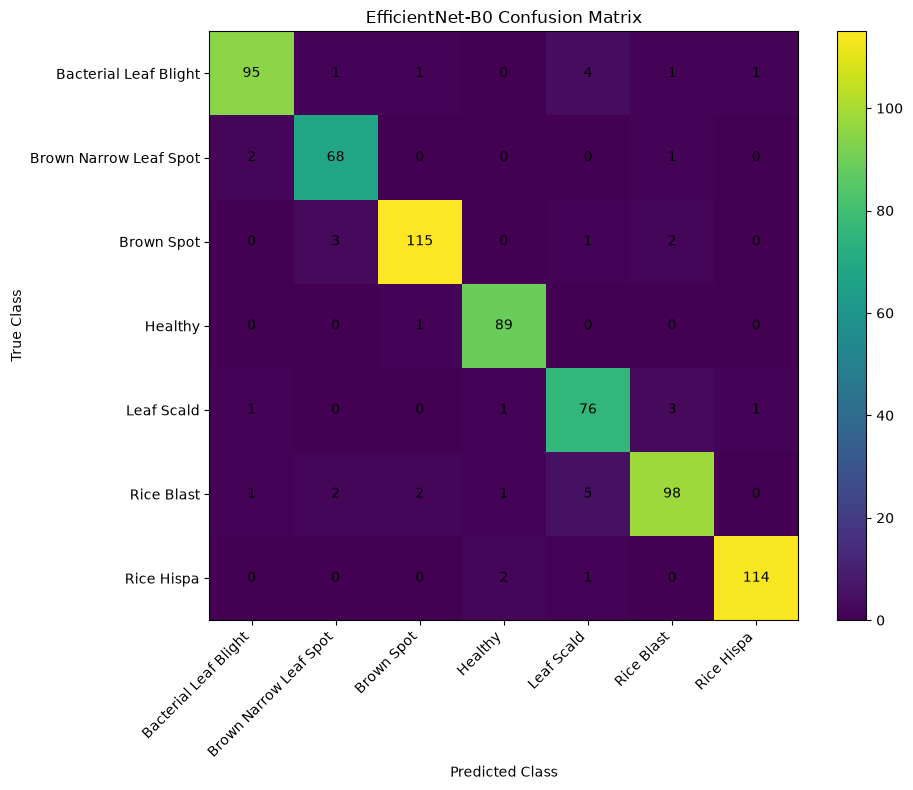

In [25]:
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(cm)

plt.title(
    "EfficientNet-B0 Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()

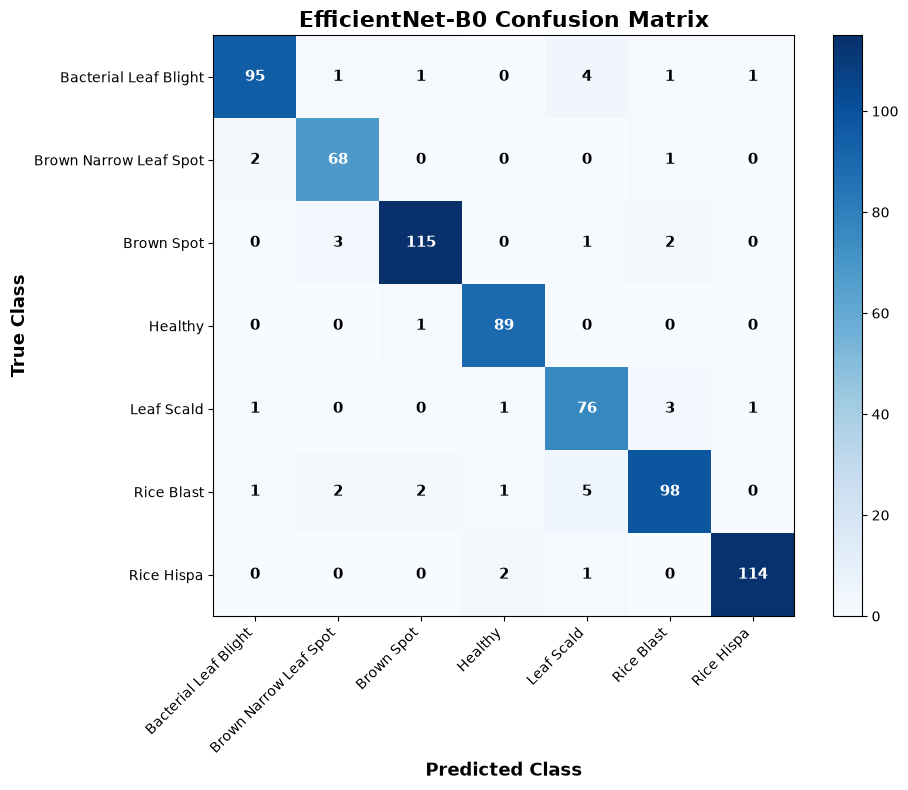

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title(
    "EfficientNet-B0 Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Class",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "True Class",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right",
    fontsize=10
)

plt.yticks(
    range(len(class_names)),
    class_names,
    fontsize=10
)

# ============================================================
# WRITE VALUES INSIDE CELLS
# ============================================================

threshold = cm.max() / 2.0

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white" if cm[i, j] > threshold else "black"
        )

# ============================================================
# COLORBAR
# ============================================================

cbar = plt.colorbar()

cbar.ax.tick_params(
    labelsize=10
)

plt.tight_layout()

plt.show()

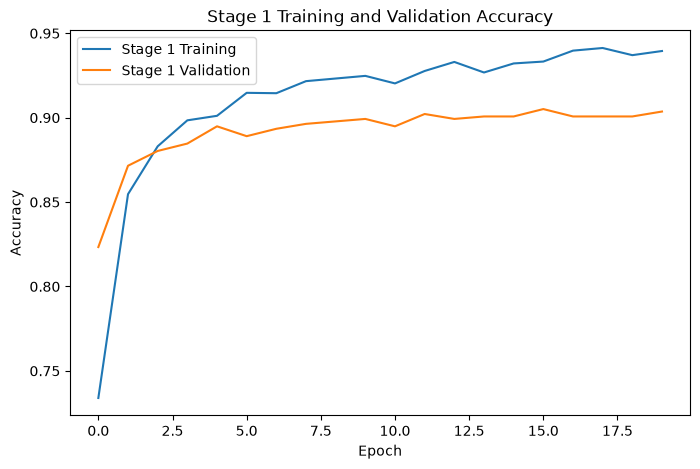

In [26]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_stage1.history["accuracy"],
    label="Stage 1 Training"
)

plt.plot(
    history_stage1.history["val_accuracy"],
    label="Stage 1 Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Stage 1 Training and Validation Accuracy"
)

plt.legend()

plt.show()

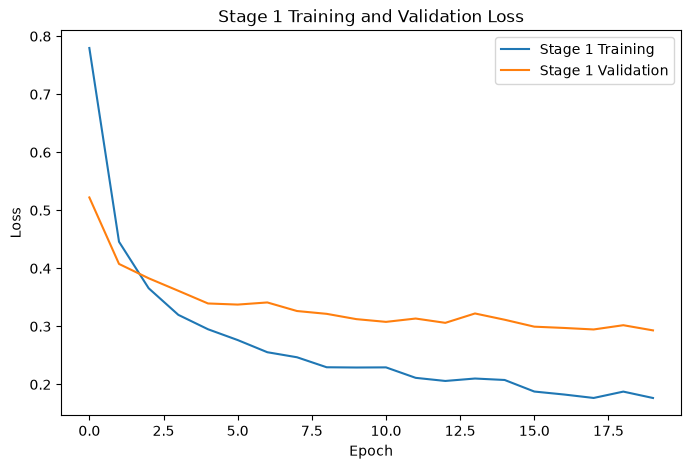

In [27]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_stage1.history["loss"],
    label="Stage 1 Training"
)

plt.plot(
    history_stage1.history["val_loss"],
    label="Stage 1 Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Stage 1 Training and Validation Loss"
)

plt.legend()

plt.show()

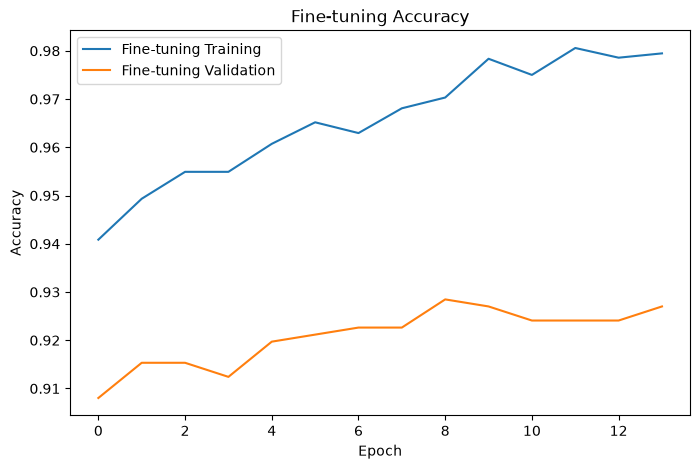

In [29]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_finetune.history["accuracy"],
    label="Fine-tuning Training"
)

plt.plot(
    history_finetune.history["val_accuracy"],
    label="Fine-tuning Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Fine-tuning Accuracy"
)

plt.legend()

plt.show()

In [30]:
import tensorflow as tf
from pathlib import Path

print("TensorFlow:", tf.__version__)

MODEL_PATH = Path(
    r"D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras"
)

OUTPUT_DIR = Path(
    r"D:\Rice Final model\8_29_26"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Model:", MODEL_PATH)
print("Output:", OUTPUT_DIR)

TensorFlow: 2.21.0
Model: D:\Rice Final model\8_29_26rice_efficientnetb0_finetuned_best.keras
Output: D:\Rice Final model\8_29_26


In [31]:
model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Model loaded successfully.")

model.summary()

Model loaded successfully.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 8, 8, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 7)                   │           8,967 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,151,514 (31.10 MB)

 Trainable params: 2,046,487 (7.81 MB)

 Non-trainable params: 2,012,051 (7.68 MB)

 Optimizer params: 4,092,976 (15.61 MB)

In [32]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)

tflite_model = converter.convert()

FLOAT32_PATH = (
    OUTPUT_DIR /
    "rice_efficientnetb0_float32.tflite"
)

with open(
    FLOAT32_PATH,
    "wb"
) as f:

    f.write(tflite_model)

print("Float32 TFLite model saved:")
print(FLOAT32_PATH)

print(
    "Size:",
    FLOAT32_PATH.stat().st_size / (1024 * 1024),
    "MB"
)

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpd9dw9oal\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpd9dw9oal\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpd9dw9oal'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2242192660368: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2242192656720: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2242227180688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227179728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227176080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227182032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227179344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181456: TensorSpec(shape=(), dtype=tf.resource

In [33]:
interpreter = tf.lite.Interpreter(
    model_path=str(FLOAT32_PATH)
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("INPUT")
print(input_details)

print("\nOUTPUT")
print(output_details)

INPUT
[{'name': 'serving_default_input_layer_1:0', 'index': 0, 'shape': array([  1, 256, 256,   3], dtype=int32), 'shape_signature': array([ -1, 256, 256,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

OUTPUT
[{'name': 'StatefulPartitionedCall_1:0', 'index': 486, 'shape': array([1, 7], dtype=int32), 'shape_signature': array([-1,  7], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


D:\rice_tf\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [38]:
import numpy as np
import tensorflow as tf

CALIBRATION_DIR = Path(
    r"D:\Rice Final model\Dataset\Train_640"
)

CALIBRATION_SAMPLES = 200

In [39]:
def representative_dataset():

    calibration_ds = tf.keras.utils.image_dataset_from_directory(

        CALIBRATION_DIR,

        image_size=(256, 256),

        batch_size=1,

        shuffle=True,

        seed=42
    )

    count = 0

    for images, labels in calibration_ds:

        # Convert to float32
        images = tf.cast(
            images,
            tf.float32
        )

        yield [
            images.numpy()
        ]

        count += 1

        if count >= CALIBRATION_SAMPLES:
            break

In [36]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

converter.representative_dataset = (
    representative_dataset
)

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8_model = converter.convert()

INT8_PATH = (
    OUTPUT_DIR /
    r"D:\Rice Final model\8_29_26\rice_efficientnetb0_int8.tflite"
)

with open(
    INT8_PATH,
    "wb"
) as f:

    f.write(tflite_int8_model)

print("INT8 TFLite model saved:")
print(INT8_PATH)

print(
    "Size:",
    INT8_PATH.stat().st_size / (1024 * 1024),
    "MB"
)

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpoxlm6guz\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpoxlm6guz\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpoxlm6guz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2242192660368: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2242192656720: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2242227180688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227179728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227176080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227182032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227179344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2242227181456: TensorSpec(shape=(), dtype=tf.resource

D:\rice_tf\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'D:\\Rice Final model\\Dataset\\Train_640'

In [40]:
import tensorflow as tf

interpreter_int8 = tf.lite.Interpreter(
    model_path=str(INT8_FILE)
)

interpreter_int8.allocate_tensors()

input_details_int8 = (
    interpreter_int8.get_input_details()
)

output_details_int8 = (
    interpreter_int8.get_output_details()
)

print("======================================")
print("INT8 MODEL INPUT")
print("======================================")

print(input_details_int8)

print("\n======================================")
print("INT8 MODEL OUTPUT")
print("======================================")

print(output_details_int8)

NameError: name 'INT8_FILE' is not defined

In [ ]:
print(
    "Input dtype:",
    input_details_int8[0]["dtype"]
)

print(
    "Output dtype:",
    output_details_int8[0]["dtype"]
)

In [ ]:
keras_size = (
    MODEL_PATH.stat().st_size
    / (1024 * 1024)
)

float32_size = (
    FLOAT32_PATH.stat().st_size
    / (1024 * 1024)
)

int8_size = (
    INT8_PATH.stat().st_size
    / (1024 * 1024)
)

print("=" * 60)
print("MODEL SIZE COMPARISON")
print("=" * 60)

print(
    f"Keras model:       {keras_size:.2f} MB"
)

print(
    f"Float32 TFLite:    {float32_size:.2f} MB"
)

print(
    f"INT8 TFLite:       {int8_size:.2f} MB"
)

In [ ]:
print("=" * 60)
print("TFLITE MODELS")
print("=" * 60)

print("\nFloat32:")
print(FLOAT32_PATH)

print("\nINT8:")
print(INT8_PATH)

print("\nFloat32 size:")
print(f"{float32_size:.2f} MB")

print("\nINT8 size:")
print(f"{int8_size:.2f} MB")

print(
    "\nCompression:",
    f"{((1 - int8_size / float32_size) * 100):.2f}%"
)

In [41]:
import json

with open(
    r"D:\Rice Final model\8_29_26\history_stage1.json",
    "w"
) as f:
    json.dump(
        history_stage1.history,
        f
    )

with open(
    r"D:\Rice Final model\8_29_26\history_finetune.json",
    "w"
) as f:
    json.dump(
        history_finetune.history,
        f
    )

print("Training histories saved successfully.")

Training histories saved successfully.


In [2]:
import tensorflow as tf
from pathlib import Path

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
BEST_FINETUNED = (
    r"D:\Rice Final model\8_29_26"
    r"rice_efficientnetb0_finetuned_best.keras"
)

model = tf.keras.models.load_model(BEST_FINETUNED)

In [4]:
BEST_FINETUNED = Path(
    r"D:\Rice Final model\8_29_26"
    r"rice_efficientnetb0_finetuned_best.keras"
)

model = tf.keras.models.load_model(BEST_FINETUNED)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 256, 256, 3)
Output shape: (None, 7)


In [5]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

OUTPUT_PATH = Path(
    r"D:\Rice Final model\8_29_26"
    r"rice_model_flutter_float32.tflite"
)

with open(OUTPUT_PATH, "wb") as f:
    f.write(tflite_model)

print("TFLite model created successfully!")
print("Saved to:", OUTPUT_PATH)
print("Size:", OUTPUT_PATH.stat().st_size / (1024 * 1024), "MB")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmp7qi0gpee\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmp7qi0gpee\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmp7qi0gpee'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2402871902672: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2402871902288: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2402834032272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834033232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834032464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402759227920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834034192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834029392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834033040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402834034000: TensorSpec(shape=(), dtype=tf.resource

In [8]:
import tkinter as tk
from tkinter import filedialog, messagebox
from PIL import Image, ImageTk
import tensorflow as tf
import numpy as np
from pathlib import Path
import time


# ============================================================
# SETTINGS
# ============================================================

MODEL_PATH = Path(
    r"D:\Rice Final model\8_29_26"
    r"rice_model_flutter_float32.tflite"
)

IMAGE_SIZE = 256

CLASS_NAMES = [
    "Bacterial Leaf Blight",
    "Brown Narrow Leaf Spot",
    "Brown Spot",
    "Healthy",
    "Leaf Scald",
    "Rice Blast",
    "Rice Hispa"
]


# ============================================================
# LOAD TFLITE MODEL
# ============================================================

try:
    interpreter = tf.lite.Interpreter(
        model_path=str(MODEL_PATH)
    )

    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    print("Model loaded successfully.")
    print("Input shape:", input_details[0]["shape"])
    print("Input dtype:", input_details[0]["dtype"])
    print("Output shape:", output_details[0]["shape"])
    print("Output dtype:", output_details[0]["dtype"])

except Exception as e:
    raise RuntimeError(
        f"Could not load TFLite model:\n{e}"
    )


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def predict_image(image_path):

    try:
        # Load image
        image = Image.open(image_path).convert("RGB")

        # Resize to model input
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        # Convert to NumPy
        image_array = np.array(
            image,
            dtype=np.float32
        )

        # Add batch dimension
        input_data = np.expand_dims(
            image_array,
            axis=0
        )

        # Set input
        interpreter.set_tensor(
            input_details[0]["index"],
            input_data
        )

        # Inference timing
        start_time = time.perf_counter()

        interpreter.invoke()

        end_time = time.perf_counter()

        inference_time = (
            end_time - start_time
        ) * 1000

        # Get output
        output = interpreter.get_tensor(
            output_details[0]["index"]
        )

        probabilities = output[0]

        # Best prediction
        predicted_index = int(
            np.argmax(probabilities)
        )

        confidence = float(
            probabilities[predicted_index]
        )

        predicted_class = CLASS_NAMES[
            predicted_index
        ]

        return (
            predicted_class,
            confidence,
            inference_time,
            probabilities
        )

    except Exception as e:
        messagebox.showerror(
            "Prediction Error",
            str(e)
        )


# ============================================================
# UPLOAD IMAGE
# ============================================================

def upload_image():

    file_path = filedialog.askopenfilename(
        title="Select Rice Leaf Image",
        filetypes=[
            (
                "Image Files",
                "*.jpg *.jpeg *.png *.bmp *.webp"
            ),
            ("All Files", "*.*")
        ]
    )

    if not file_path:
        return

    # Display image
    image = Image.open(file_path).convert("RGB")

    display_image = image.copy()
    display_image.thumbnail((500, 400))

    photo = ImageTk.PhotoImage(
        display_image
    )

    image_label.configure(
        image=photo
    )

    image_label.image = photo

    # Show file name
    file_label.config(
        text=f"Image: {Path(file_path).name}"
    )

    # Reset result
    result_label.config(
        text="Analyzing...",
        fg="black"
    )

    confidence_label.config(
        text=""
    )

    time_label.config(
        text=""
    )

    # Run prediction
    result = predict_image(file_path)

    if result is None:
        return

    (
        predicted_class,
        confidence,
        inference_time,
        probabilities
    ) = result

    confidence_percent = confidence * 100

    # Display prediction
    result_label.config(
        text=predicted_class,
        fg="green"
    )

    confidence_label.config(
        text=f"Confidence: {confidence_percent:.2f}%"
    )

    time_label.config(
        text=f"Inference time: {inference_time:.2f} ms"
    )

    # Print all class probabilities
    print("\n" + "=" * 60)
    print("PREDICTION")
    print("=" * 60)

    print(
        "Predicted:",
        predicted_class
    )

    print(
        "Confidence:",
        f"{confidence_percent:.2f}%"
    )

    print(
        "Inference time:",
        f"{inference_time:.2f} ms"
    )

    print("\nAll class probabilities:")

    for i, probability in enumerate(
        probabilities
    ):
        print(
            f"{CLASS_NAMES[i]:30s} "
            f"{probability * 100:.2f}%"
        )


# ============================================================
# GUI
# ============================================================

root = tk.Tk()

root.title(
    "Rice Disease Detection - TFLite"
)

root.geometry(
    "700x750"
)

root.resizable(
    False,
    False
)


# ============================================================
# TITLE
# ============================================================

title_label = tk.Label(
    root,
    text="Rice Disease Detection",
    font=("Arial", 26, "bold")
)

title_label.pack(
    pady=(25, 5)
)


subtitle_label = tk.Label(
    root,
    text="EfficientNet-B0 • TensorFlow Lite",
    font=("Arial", 13)
)

subtitle_label.pack(
    pady=(0, 20)
)


# ============================================================
# IMAGE AREA
# ============================================================

image_frame = tk.Frame(
    root,
    width=520,
    height=420,
    relief=tk.GROOVE,
    borderwidth=2
)

image_frame.pack(
    pady=10
)

image_frame.pack_propagate(False)


image_label = tk.Label(
    image_frame,
    text="Upload a rice leaf image",
    font=("Arial", 16),
    bg="white"
)

image_label.pack(
    expand=True
)


# ============================================================
# FILE NAME
# ============================================================

file_label = tk.Label(
    root,
    text="No image selected",
    font=("Arial", 11)
)

file_label.pack(
    pady=5
)


# ============================================================
# UPLOAD BUTTON
# ============================================================

upload_button = tk.Button(
    root,
    text="UPLOAD IMAGE",
    command=upload_image,
    font=("Arial", 14, "bold"),
    padx=30,
    pady=12
)

upload_button.pack(
    pady=15
)


# ============================================================
# RESULT
# ============================================================

result_title = tk.Label(
    root,
    text="Prediction",
    font=("Arial", 13, "bold")
)

result_title.pack(
    pady=(10, 2)
)


result_label = tk.Label(
    root,
    text="Waiting for image...",
    font=("Arial", 22, "bold")
)

result_label.pack(
    pady=5
)


confidence_label = tk.Label(
    root,
    text="",
    font=("Arial", 15)
)

confidence_label.pack(
    pady=3
)


time_label = tk.Label(
    root,
    text="",
    font=("Arial", 11)
)

time_label.pack(
    pady=3
)


# ============================================================
# START APPLICATION
# ============================================================

root.mainloop()

Model loaded successfully.
Input shape: [  1 256 256   3]
Input dtype: <class 'numpy.float32'>
Output shape: [1 7]
Output dtype: <class 'numpy.float32'>

PREDICTION
Predicted: Rice Blast
Confidence: 73.57%
Inference time: 28.74 ms

All class probabilities:
Bacterial Leaf Blight          23.53%
Brown Narrow Leaf Spot         2.80%
Brown Spot                     0.07%
Healthy                        0.00%
Leaf Scald                     0.03%
Rice Blast                     73.57%
Rice Hispa                     0.00%

PREDICTION
Predicted: Rice Blast
Confidence: 90.27%
Inference time: 24.32 ms

All class probabilities:
Bacterial Leaf Blight          9.18%
Brown Narrow Leaf Spot         0.21%
Brown Spot                     0.19%
Healthy                        0.00%
Leaf Scald                     0.14%
Rice Blast                     90.27%
Rice Hispa                     0.01%
